<a href="https://colab.research.google.com/github/Victor-MorenoMontero/LAB_SIS420/blob/main/Lab2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Ejercicio de programación Regresión Lineal Multiple

In [1]:
# utilizado para manejos de directorios y rutas
import os

# Computacion vectorial y cientifica para python
import numpy as np

# Librerias para graficación (trazado de gráficos)
from matplotlib import pyplot
from mpl_toolkits.mplot3d import Axes3D  # Necesario para graficar superficies 3D

# llama a matplotlib a embeber graficas dentro de los cuadernillos
%matplotlib inline

import pandas as pd


In [2]:
from google.colab import drive
drive.mount("/content/gdrive")

Mounted at /content/gdrive


## 2 Regresión lineal con multiples variables

Se implementa la regresion lineal multivariable para predecir el precio de las casas. El archivo `YearPredictionMSD.txt` contiene información numérica relacionada con canciones. Cada fila representa una canción y las columnas contienen diferentes características de la canción. Para aplicar regresión, algunas columnas se utilizan como variables independientes (X), mientras que una columna se selecciona como variable dependiente (y), que es la que se desea predecir.

<a id="section4"></a>
### 2.1 Normalización de caracteristicas

Al visualizar los datos se puede observar que las caracteristicas tienen diferentes magnitudes, por lo cual se debe transformar cada valor en una escala de valores similares, esto con el fin de que el descenso por el gradiente pueda converger mas rapidamente.

In [26]:
# Cargar datos
# data = np.loadtxt(os.path.join('Datasets', 'ex1data2.txt'), delimiter=',')
data = pd.read_csv("/content/gdrive/MyDrive/datasets/YearPredictionMSD.txt", header=None)

print(data.head())
print(data.shape)


     0         1         2         3         4         5         6         7   \
0  2001  49.94357  21.47114  73.07750   8.74861 -17.40628 -13.09905 -25.01202   
1  2001  48.73215  18.42930  70.32679  12.94636 -10.32437 -24.83777   8.76630   
2  2001  50.95714  31.85602  55.81851  13.41693  -6.57898 -18.54940  -3.27872   
3  2001  48.24750  -1.89837  36.29772   2.58776   0.97170 -26.21683   5.05097   
4  2001  50.97020  42.20998  67.09964   8.46791 -15.85279 -16.81409 -12.48207   

         8         9   ...        81         82        83        84        85  \
0 -12.23257   7.83089  ...  13.01620  -54.40548  58.99367  15.37344   1.11144   
1  -0.92019  18.76548  ...   5.66812  -19.68073  33.04964  42.87836  -9.90378   
2  -2.35035  16.07017  ...   3.03800   26.05866 -50.92779  10.93792  -0.07568   
3 -10.34124   3.55005  ...  34.57337 -171.70734 -16.96705 -46.67617 -12.51516   
4  -9.37636  12.63699  ...   9.92661  -55.95724  64.92712 -17.72522  -1.49237   

         86         87    

In [27]:
y = data.iloc[:, 0].values
X = data.iloc[:, 1:].values
m = y.size

In [28]:
print(X.shape)
print(y.shape)
print(y.size)

(515345, 90)
(515345,)
515345


La desviación estándar es una forma de medir cuánta variación hay en el rango de valores de una característica en particular (la mayoría de los puntos caeran en un rango de ± 2 en relación a la desviaciones estándar de la media); esta es una alternativa a tomar el rango de valores (max-min). En `numpy`, se puede usar la función `std` para calcular la desviacion estandar.

Por ejemplo, la caracteristica`X[:, 0]` contiene todos los valores de $x_1$ (tamaño de las casas) en el conjunto de entrenamiento, entonces `np.std(X[:, 0])` calcula la desviacion estandar de los tamaños de las casas.
En el momento en que se llama a la función `featureNormalize`, la columna adicional de unos correspondiente a $ x_0 = 1 $ aún no se ha agregado a $ X $.

<div class="alert alert-block alert-warning">
**Notas para la implementación:** Cuando se normalize una caracteristica, es importante almacenar los valores usados para la normalización - el valor de la media y el valor de la desviación estandar usado para los calculos. Despues de aprender los parametros del modelo, se deseara predecir los precios de casas que no se han visto antes. Dado un nuevo valor de x (area del living room y el numero de dormitorios), primero se debe normalizar x usando la media y la desviacion estandar que se empleo anteriormente en el conjunto de entrenamiento para entrenar el modelo.
</div>
<a id="featureNormalize"></a>

In [29]:
# Se normalizan los datos
def featureNormalize(X):

  X_norm = X.copy()
  mu = np.zeros(X.shape[1])
  sigma = np.zeros(X.shape[1])

  mu = np.mean(X, axis=0)
  sigma = np.std(X, axis=0)
  X_norm = (X - mu) / sigma

  return X_norm, mu, sigma


In [30]:
# llama featureNormalize con los datos cargados
#X_norm, mu, sigma = featureNormalize(X)
X_norm, mu, sigma = featureNormalize(X)

print(X)
print('Media calculada:', mu)
print('Desviación estandar calculada:', sigma)
print(X_norm)

[[ 4.994357e+01  2.147114e+01  7.307750e+01 ... -1.822230e+00
  -2.746348e+01  2.263270e+00]
 [ 4.873215e+01  1.842930e+01  7.032679e+01 ...  1.204941e+01
   5.843453e+01  2.692061e+01]
 [ 5.095714e+01  3.185602e+01  5.581851e+01 ... -5.859000e-02
   3.967068e+01 -6.634500e-01]
 ...
 [ 4.512852e+01  1.265758e+01 -3.872018e+01 ... -6.071710e+00
   5.396319e+01 -8.093640e+00]
 [ 4.416614e+01  3.238368e+01 -3.349710e+00 ...  2.032240e+01
   1.483107e+01  3.974909e+01]
 [ 5.185726e+01  5.911655e+01  2.639436e+01 ... -5.515120e+00
   3.235602e+01  1.217352e+01]]
Media calculada: [ 4.33871256e+01  1.28955420e+00  8.65834709e+00  1.16412447e+00
 -6.55360070e+00 -9.52197520e+00 -2.39108942e+00 -1.79323551e+00
  3.72787581e+00  1.88238491e+00 -1.46527016e-01  2.54606336e+00
  3.37140056e+01  2.43935938e+03  1.96773420e+03  1.51485990e+03
  9.10981344e+02  8.79146721e+02  6.03737434e+02  5.17579339e+02
  3.93962215e+02  3.25733170e+02  2.88885085e+02  2.91973238e+02
  4.30319687e+01  4.33148725e

Despues de `featureNormalize` la funcion es provada, se añade el temino de interseccion a `X_norm`:

In [31]:
# Añade el termino de interseccion a X
# (Columna de unos para X0)
X = np.concatenate([np.ones((m, 1)), X_norm], axis=1)

In [32]:
print(X)

[[ 1.          1.08057482  0.39126538 ... -0.47059907 -0.2559771
   0.04229179]
 [ 1.          0.88091936  0.33229247 ...  0.56874417  0.20694004
   1.15858664]
 [ 1.          1.24762241  0.5925996  ... -0.338457    0.10581886
  -0.0902076 ]
 ...
 [ 1.          0.28700113  0.22039472 ... -0.78899461  0.18284332
  -0.42658949]
 [ 1.          0.12839022  0.60282948 ...  1.18860427 -0.02804549
   1.73936161]
 [ 1.          1.39597218  1.12110622 ... -0.74729168  0.06639907
   0.49095174]]


<a id="section5"></a>
### 2.2 Descenso por el gradiente

En el ejemplo anterior se implemento el descenso por el gradiente para un problema de regresion univariable. La unica diferencia es que ahora existe una caracteristica adicional en la matriz $X$. La función de hipótesis y la regla de actualización del descenso del gradiente por lotes permanecen sin cambios.

La implementacion de las funciones `computeCostMulti` y `gradientDescentMulti` son similares a la funcion de costo y función de descenso por el gradiente de la regresión lineal multiple es similar al de la regresion lineal multivariable. Es importante garantizar que el codigo soporte cualquier numero de caracteristicas y esten bien vectorizadas.

Se puede utilizar `shape`, propiedad de los arrays `numpy`, para identificar cuantas caracteristicas estan consideradas en el dataset.

<div class="alert alert-block alert-warning">
**Nota de implementación:** En el caso de multivariables, la función de costo puede se escrita considerando la forma vectorizada de la siguiente manera:

$$ J(\theta) = \frac{1}{2m}(X\theta - \vec{y})^T(X\theta - \vec{y}) $$

donde:

$$ X = \begin{pmatrix}
- (x^{(1)})^T - \\
- (x^{(2)})^T - \\
\vdots \\
- (x^{(m)})^T - \\ \\
\end{pmatrix} \qquad \mathbf{y} = \begin{bmatrix} y^{(1)} \\ y^{(2)} \\ \vdots \\ y^{(m)} \\\end{bmatrix}$$

La version vectorizada es eficiente cuando se trabaja con herramientas de calculo numericos computacional como `numpy`.
</div>

<a id="computeCostMulti"></a>

In [33]:
print(X.shape)

(515345, 91)


In [34]:
def computeCostMulti(X, y, theta):
    # Inicializa algunos valores utiles
    m = y.shape[0] # numero de ejemplos de entrenamiento

    J = 0

    # h = np.dot(X, theta)

    J = (1/(2 * m)) * np.sum(np.square(np.dot(X, theta) - y))

    return J


In [35]:
def gradientDescentMulti(X, y, theta, alpha, num_iters):

    # Inicializa algunos valores
    m = y.shape[0] # numero de ejemplos de entrenamiento

    # realiza una copia de theta, el cual será acutalizada por el descenso por el gradiente

    theta = theta.copy()

    J_history = []

    for i in range(num_iters):
        theta = theta - (alpha / m) * (np.dot(X, theta) - y).dot(X)
        J_history.append(computeCostMulti(X, y, theta))

    return theta, J_history

#### 3.2.1 Seleccionando coheficientes de aprendizaje


theta calculado por el descenso por el gradiente: [ 1.99830681e+03  4.86404892e+00 -2.46578361e+00 -1.31786306e+00
 -5.61252335e-01 -2.26970998e-01 -2.32207070e+00  2.51468052e-01
 -6.72087506e-01 -5.68262926e-01  1.80083476e-01 -1.45953177e-01
 -2.65084367e-01  9.20628335e-01  5.66420898e-01 -5.52455498e-01
  7.80908409e-01  2.34113500e-01  6.97978005e-01  5.92768499e-01
  7.62451770e-01  1.57568566e-01  6.48273077e-02  1.18577221e+00
  4.01594664e-01 -3.01634578e-01  3.38224608e-02  7.43520474e-01
  9.38350615e-02  1.48261279e-01 -1.09193592e-02 -1.54035063e-01
 -1.06432460e-01 -3.94792805e-01  1.21745589e-01  2.56674004e-02
 -5.31596386e-01 -5.63825043e-02  3.56480314e-01  4.37228801e-01
 -3.34881579e-01 -3.06904841e-01 -9.95702346e-02 -1.13705530e-01
 -7.41029856e-02 -1.49360654e-01  3.28358612e-01  2.33041675e-01
 -4.42428006e-01  1.40164214e-02  2.14285014e-01  5.24051557e-02
 -1.03876015e-01  9.85561400e-02  3.27169413e-02 -2.23150808e-02
  1.61429840e-02 -5.27001269e-01  5.5498

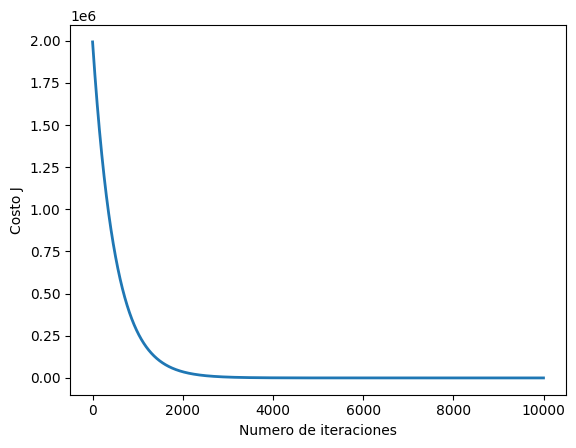

In [41]:
# Elegir algun valor para alpha (probar varias alternativas)
alpha = 0.001 # alpha = 0.003
num_iters = 10000

# inicializa theta y ejecuta el descenso por el gradiente
theta = np.zeros(X.shape[1])
theta, J_history = gradientDescentMulti(X, y, theta, alpha, num_iters)

# Grafica la convergencia del costo
pyplot.plot(np.arange(len(J_history)), J_history, lw=2)
pyplot.xlabel('Numero de iteraciones')
pyplot.ylabel('Costo J')

# Muestra los resultados del descenso por el gradiente
print('theta calculado por el descenso por el gradiente: {:s}'.format(str(theta)))

# Mostrar el costo final
print('Costo final:', J_history[-1])

theta calculado por el descenso por el gradiente: [ 1.99839708e+03  5.24083166e+00 -2.79099706e+00 -1.42792675e+00
 -2.81939502e-01 -2.88606103e-01 -2.57550671e+00  8.40482006e-02
 -7.85533663e-01 -7.03831976e-01  2.27602368e-01 -4.48289460e-01
 -1.21126618e-01  1.02275122e+00  6.19674910e-01 -5.58877548e-01
  7.53512614e-01  2.29039687e-01  8.36541195e-01  6.03002991e-01
  7.14805196e-01  1.54288125e-01 -7.08627646e-02  1.35151441e+00
  4.29124946e-01 -4.11284034e-01  4.77113723e-02  8.36422730e-01
  1.07443185e-01  1.44910051e-01 -3.52835230e-02 -1.42917457e-01
 -1.04877826e-01 -3.95562887e-01  1.19770200e-01  6.50128404e-02
 -5.64407568e-01 -8.81020001e-02  3.25363157e-01  3.91658531e-01
 -3.46854967e-01 -2.56577800e-01 -9.54351446e-02 -9.90727340e-02
 -8.64488737e-02 -1.37061963e-01  3.52781717e-01  2.14399580e-01
 -5.21042411e-01  5.26353027e-02  2.26864438e-01  3.20401868e-02
 -1.22664743e-01  1.24971338e-01  3.87643319e-02 -6.55637351e-03
  2.09043008e-02 -5.71409368e-01  5.3604

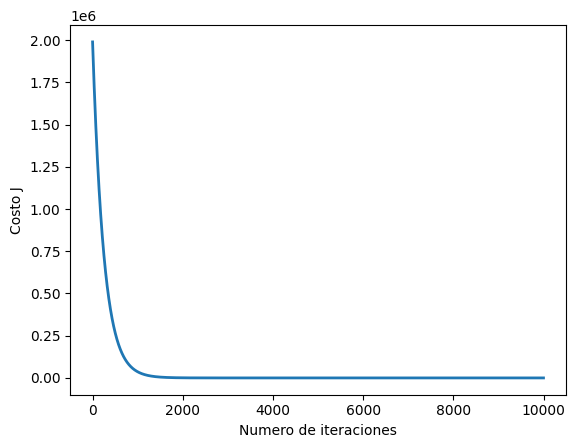

In [36]:
# Elegir algun valor para alpha (probar varias alternativas)
alpha = 0.002 # alpha = 0.003
num_iters = 10000

# inicializa theta y ejecuta el descenso por el gradiente
theta = np.zeros(X.shape[1])
theta_002, J_history_002 = gradientDescentMulti(X, y, theta, alpha, num_iters)

# Grafica la convergencia del costo
pyplot.plot(np.arange(len(J_history_002)), J_history_002, lw=2)
pyplot.xlabel('Numero de iteraciones')
pyplot.ylabel('Costo J')

# Muestra los resultados del descenso por el gradiente
print('theta calculado por el descenso por el gradiente: {:s}'.format(str(theta_002)))

# Mostrar el costo final
print('Costo final:', J_history_002[-1])

theta calculado por el descenso por el gradiente: [ 1.99839708e+03  5.29394156e+00 -2.86278943e+00 -1.47533272e+00
 -1.26074694e-01 -3.11698396e-01 -2.69866918e+00 -3.57321131e-03
 -8.09390751e-01 -7.38152988e-01  2.14033445e-01 -5.90736632e-01
 -6.34158583e-02  1.03669552e+00  6.26460824e-01 -5.44948089e-01
  7.09984332e-01  2.28929595e-01  8.57958820e-01  6.02695345e-01
  6.97177634e-01  1.58361542e-01 -9.55730677e-02  1.39072156e+00
  4.30154875e-01 -4.27289195e-01  4.89620166e-02  8.56197641e-01
  1.12320220e-01  1.44080350e-01 -4.21619216e-02 -1.40659672e-01
 -1.01793156e-01 -4.02424491e-01  1.26249124e-01  7.53333375e-02
 -5.69833135e-01 -1.02806358e-01  3.13592629e-01  3.71875195e-01
 -3.50916064e-01 -2.43997189e-01 -9.39185609e-02 -9.96846222e-02
 -9.00230835e-02 -1.33054564e-01  3.62811061e-01  2.13132904e-01
 -5.38870354e-01  5.92916018e-02  2.32119010e-01  2.54811054e-02
 -1.24162778e-01  1.33512154e-01  3.89550433e-02 -4.18412074e-03
  3.10454477e-02 -5.82552351e-01  5.2475

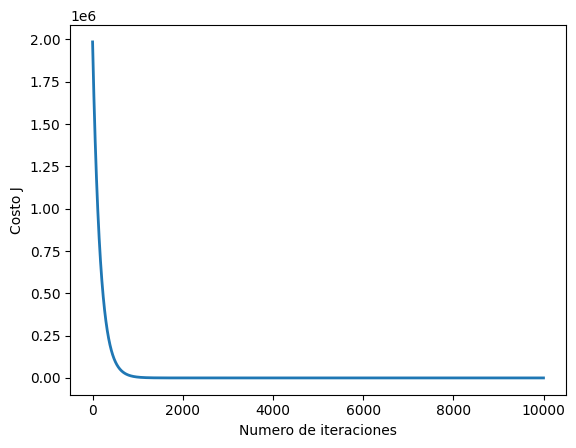

In [15]:
# Elegir algun valor para alpha (probar varias alternativas)
alpha = 0.003 # alpha = 0.003
num_iters = 10000

# inicializa theta y ejecuta el descenso por el gradiente
theta = np.zeros(X.shape[1])
theta_003, J_history_003 = gradientDescentMulti(X, y, theta, alpha, num_iters)

# Grafica la convergencia del costo
pyplot.plot(np.arange(len(J_history_003)), J_history_003, lw=2)
pyplot.xlabel('Numero de iteraciones')
pyplot.ylabel('Costo J')

# Muestra los resultados del descenso por el gradiente
print('theta calculado por el descenso por el gradiente: {:s}'.format(str(theta_003)))

# Mostrar el costo final
print('Costo final:', J_history_003[-1])

In [43]:
print('Costo final alpha = 0.001:', J_history[-1])
print('Costo final alpha = 0.002:', J_history_002[-1])
print('Costo final alpha = 0.003:', J_history_003[-1])

Costo final alpha = 0.001: 45.690063181685105
Costo final alpha = 0.002: 45.597700889584864
Costo final alpha = 0.003: 45.587592681388514


In [46]:
# Seleccionar las características de una canción
X_nueva = data.iloc[3000, 1:].values

# Normalizar utilizando la misma media y desviación estándar
# calculadas durante el entrenamiento
X_nueva_norm = (X_nueva - mu) / sigma

# Agregar el término independiente
X_array = np.concatenate([[1], X_nueva_norm])

# Realizar la inferencia con el mejor theta
prediccion = np.dot(X_array, theta_003)

# Mostrar resultados
print('Año real:', y[3000])
print('Año predicho:', prediccion)
print('Año predicho redondeado:', round(prediccion))

Año real: 2004
Año predicho: 2001.521981202155
Año predicho redondeado: 2002


<a id="section7"></a>
### 2.3 Ecuacion de la Normal

Una manera de calcular rapidamente el modelo de una regresion lineal es:

$$ \theta = \left( X^T X\right)^{-1} X^T\vec{y}$$

Utilizando esta formula no requiere que se escale ninguna caracteristica, y se obtendra una solucion exacta con un solo calculo: no hay “bucles de convergencia” como en el descenso por el gradiente.

Primero se recargan los datos para garantizar que las variables no esten modificadas. Recordar que no es necesario escalar las caracteristicas, se debe agregar la columna de unos a la matriz $X$ para tener el termino de intersección($\theta_0$).

In [18]:
"Número de ejemplos:",# Cargar datos
data = np.loadtxt('/content/gdrive/MyDrive/datasets/YearPredictionMSD.txt', delimiter=',')
y = data[:, 0]
X = data[:, 1:]
m = y.size
print("Número de ejemplos:",m)

X = np.concatenate([np.ones((m, 1)), X], axis=1)
print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

Número de ejemplos: 515345
Dimensiones de X: (515345, 91)
Dimensiones de y: (515345,)


In [19]:
def normalEqn(X, y):

    theta = np.zeros(X.shape[1])

    theta = np.dot(np.dot(np.linalg.inv(np.dot(X.T,X)),X.T),y)

    return theta

In [20]:
# Calcula los parametros con la ecuación de la normal
theta = normalEqn(X, y);

# Muestra los resultados optenidos a partir de la aplicación de la ecuación de la normal
print('Theta calculado a partir de la ecuación de la normal: {:s}'.format(str(theta)));



Theta calculado a partir de la ecuación de la normal: [ 1.95103711e+03  8.75418124e-01 -5.63271164e-02 -4.36490654e-02
  3.35326083e-03 -1.47468748e-02 -2.20071726e-01 -6.73919082e-03
 -1.00897584e-01 -7.04728814e-02  2.50691291e-02 -1.65703623e-01
 -1.85480167e-03  4.70139734e-02  3.55100627e-04 -4.22581025e-04
  5.99188699e-04  4.76557935e-04  1.46665847e-03  1.92445360e-03
  2.12832389e-03  7.69871550e-04 -4.02569165e-04  7.53934986e-03
  2.81198502e-03 -3.55560501e-03  7.11382813e-05  1.58941497e-03
  5.29431505e-04  8.74511415e-04 -3.04182481e-04 -1.40497004e-03
 -1.40130314e-03 -5.55968147e-03  2.47236496e-03  1.84963210e-03
 -5.29413753e-03 -2.77273206e-04  6.79201032e-04  1.36516401e-03
 -1.71045701e-03 -1.99137811e-03 -7.64154508e-04 -1.40252362e-03
 -2.35913075e-03 -3.17985554e-03  6.81262742e-03  4.56071335e-04
 -2.07494336e-03  2.75184183e-04  1.94121271e-03  2.20058312e-04
 -1.60491529e-03  1.97091583e-03  4.90779335e-04 -8.43754305e-05
  1.62872728e-04 -1.89762160e-03  1.

In [24]:
# Seleccionar una canción del dataset
X_array = X[3000, :]

# Calcular la predicción
prediction = np.dot(X_array, theta)

print("Año real:", y[3000])
print("Año predicho:", prediction)

Año real: 2004.0
Año predicho: 2001.4971417886084
